# 01 · Data Understanding

**Brief, section 1:** run an exploratory analysis and build a correlation matrix of channels to sales, then answer three questions:

- What conclusions follow from the channel interactions and the data?
- What obstacles can come up in further processing?
- Which of the influencing factors cannot be used?

The written answers are in the last section. Figures are exported to `reports/figures/` for the presentation.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import STL

from tchibo_mmm import data, evaluate, features
from tchibo_mmm.plotting import (
    CHANNEL_COLORS, DIVERGING, INK_2, MUTED, TOTAL_COLOR, save, thousands, use_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
use_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 120)

raw = data.load_raw()
sales = data.sales_by_channel(raw)    # date x channel, missing channel-day = 0
costs = data.costs_by_channel(raw)    # date x channel, no cost = 0
y = sales.sum(axis=1).rename("total_sales")
send_outs = data.catalog_send_out_dates(raw)
PAID = data.PAID_CHANNELS

## 1. Structure and quality

In [2]:
data.load_info()

,Column,Explanations
0,date,"Date of measurement for impressions, clicks, and sales"
1,channel,Marketing channel name
2,sales_by_channel,Demand value of the marketing channel
3,impressions,"Number of impressions of the marketing channel, for catalog it is the circulation"
4,clicks,Number of Marketing Channel Clicks
5,costs,"Sum of the marketing channel costs for the day of causation, e.g. display spend of the day or cost of the catalog fo..."


In [3]:
unsorted = pd.read_excel(data.DATA_PATH, sheet_name="data")
print(f"rows: {len(raw):,} | channels: {raw.channel.nunique()} | "
      f"dates: {raw.date.min().date()} -> {raw.date.max().date()} ({raw.date.nunique()} days)")
print(f"source rows sorted by date: {unsorted.date.is_monotonic_increasing}")
print(f"duplicate (date, channel) rows: {raw.duplicated(['date', 'channel']).sum()}")
print(f"days in 2025: {(raw.date.dt.year == 2025).groupby(raw.date).any().sum()}")

g = raw.groupby("channel")
quality = pd.DataFrame({
    "rows": g.size(),
    "missing_days": data.missing_channel_days(raw),
    "impressions": g.impressions.count(),
    "clicks": g.clicks.count(),
    "costs": g.costs.count(),
    "sales<1": g.sales_by_channel.apply(lambda s: (s < 1).sum()),
}).reindex(data.ALL_CHANNELS)
quality

rows: 8,740 | channels: 12 | dates: 2023-01-01 -> 2025-01-01 (732 days)
source rows sorted by date: False
duplicate (date, channel) rows: 0
days in 2025: 1


,rows,missing_days,impressions,clicks,costs,sales<1
channel,,,,,,
SEA,732,0,732,732,732,0
Catalog,728,4,28,28,28,0
Display,732,0,732,732,732,0
Affiliate,732,0,732,732,732,0
Display Network,732,0,732,732,732,0
Social Media,732,0,732,732,732,0
PSM,732,0,0,732,732,0
Direct Type-in,732,0,0,0,0,0
SEO,732,0,0,0,0,0


**What we see:**

- **Long format, shuffled rows.** The data has one row per `(date, channel)`, in no particular order.
- **Missing channel-days:** TV has 38, Catalog 4 and Owned 2. They count as 0 sales, which affects less than 0.6 % of total sales.
- **Costs exist for only 7 channels.** Catalog has costs only on its 28 send-out days, and the 5 other channels have none at all.
- **Impressions and clicks are patchy.** PSM has no impressions, and Catalog clicks are always 0. For the Catalog, the impressions field holds the print run.

## 2. Channel overview: sales share vs cost share

In [4]:
overview = pd.DataFrame({"sales": sales.sum(), "costs": costs.sum()})
overview["sales_share"] = overview.sales / overview.sales.sum()
overview["cost_share"] = overview.costs / overview.costs.sum()
overview["attributed_ROAS"] = (overview.sales / overview.costs).where(overview.costs > 0)
overview = overview.sort_values("sales", ascending=False)
print(f"paid channels' share of attributed sales: {overview.loc[PAID, 'sales_share'].sum():.1%}")
overview.style.format({"sales": "{:,.0f}", "costs": "{:,.0f}", "sales_share": "{:.1%}",
                       "cost_share": "{:.1%}", "attributed_ROAS": "{:.2f}"}, na_rep="–")

paid channels' share of attributed sales: 63.9%


,sales,costs,sales_share,cost_share,attributed_ROAS
channel,,,,,
SEA,"151,349,850","38,508,758",26.3%,30.4%,3.93
Direct Type-in,"120,871,667",0,21.0%,0.0%,–
SEO,"80,960,365",0,14.0%,0.0%,–
Catalog,"79,890,614","38,557,298",13.9%,30.5%,2.07
Display,"64,781,110","29,804,902",11.2%,23.5%,2.17
Affiliate,"39,674,757","4,834,301",6.9%,3.8%,8.21
Display Network,"14,625,783","4,092,729",2.5%,3.2%,3.57
Social Media,"11,488,738","8,823,871",2.0%,7.0%,1.30
PSM,"6,500,012","1,998,317",1.1%,1.6%,3.25


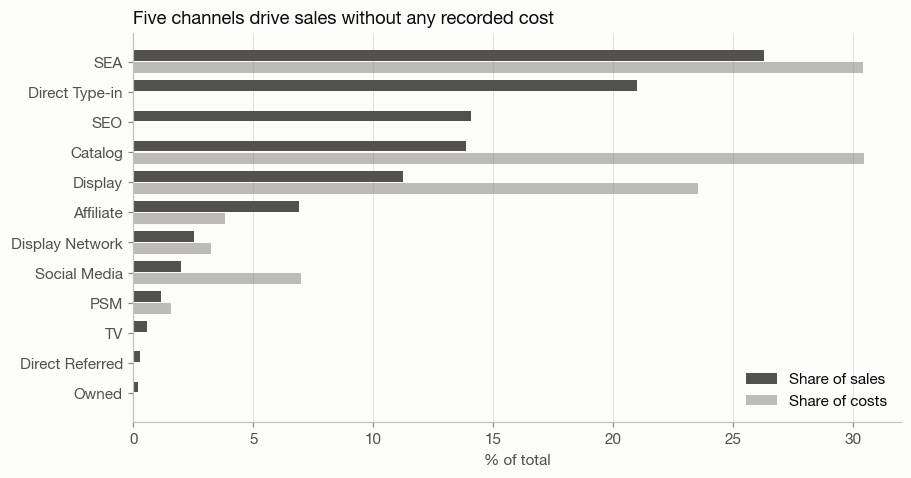

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.6))
order = overview.index[::-1]
pos = np.arange(len(order))
ax.barh(pos + 0.2, overview.loc[order, "sales_share"] * 100, height=0.36, color=INK_2, label="Share of sales")
ax.barh(pos - 0.2, overview.loc[order, "cost_share"] * 100, height=0.36, color=MUTED, alpha=0.55,
        label="Share of costs")
ax.set_yticks(pos, order)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("% of total")
ax.set_title("Five channels drive sales without any recorded cost")
ax.legend(loc="lower right")
save(fig, "01_sales_vs_cost_share");

## 3. The target: total daily sales

This is the dependent variable from the brief: the sum of `sales_by_channel` over all 12 channels, per day.

In [6]:
print(y.describe().apply("{:,.0f}".format).to_string())
yearly = y.groupby(y.index.year).sum()
print(f"\n2024 vs 2023 sales: {yearly[2024] / yearly[2023] - 1:+.1%}")
spend_year = costs[PAID].sum(axis=1).groupby(costs.index.year).sum()
print(f"2024 vs 2023 spend: {spend_year[2024] / spend_year[2023] - 1:+.1%}")
print(f"15 % of mean daily sales = {0.15 * y.mean():,.0f} (MAE budget over the full period)")

count          732
mean       787,292
std        281,843
min        218,492
25%        602,239
50%        736,961
75%        923,461
max      2,753,320

2024 vs 2023 sales: +20.7%
2024 vs 2023 spend: +12.4%
15 % of mean daily sales = 118,094 (MAE budget over the full period)


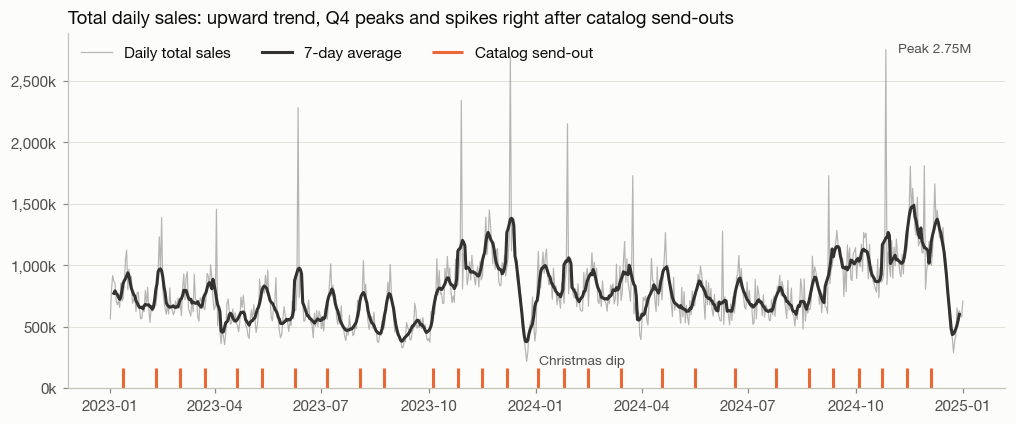

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(y.index, y, color=MUTED, lw=0.8, alpha=0.6, label="Daily total sales")
ax.plot(y.index, y.rolling(7, center=True).mean(), color=TOTAL_COLOR, lw=2, label="7-day average")
ax.vlines(send_outs, 0, y.max() * 0.06, color=CHANNEL_COLORS["Catalog"], lw=2, label="Catalog send-out")
for d, txt in [(y.idxmax(), "Peak 2.75M"), (pd.Timestamp("2023-12-24"), "Christmas dip")]:
    ax.annotate(txt, (d, y[d]), xytext=(8, 0), textcoords="offset points", color=INK_2, fontsize=9, va="center")
thousands(ax, unit="k")
ax.set_ylim(0)
ax.set_title("Total daily sales: upward trend, Q4 peaks and spikes right after catalog send-outs")
ax.legend(loc="upper left", ncols=3)
save(fig, "01_total_sales");

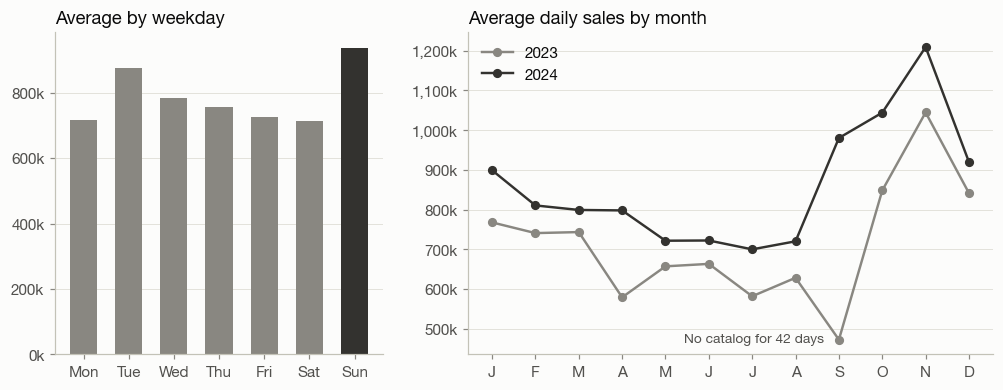

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
dow = y.groupby(y.index.dayofweek).mean()
axes[0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow, width=0.6,
            color=[TOTAL_COLOR if v == dow.max() else MUTED for v in dow])
thousands(axes[0], unit="k")
axes[0].set_title("Average by weekday")
monthly = y.groupby([y.index.year, y.index.month]).mean().unstack(0)
axes[1].plot(monthly.index, monthly[2023], color=MUTED, marker="o", ms=5, label="2023")
axes[1].plot(monthly.index, monthly[2024], color=TOTAL_COLOR, marker="o", ms=5, label="2024")
axes[1].set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
thousands(axes[1], unit="k")
axes[1].set_title("Average daily sales by month")
axes[1].annotate("No catalog for 42 days", (9, monthly.loc[9, 2023]), xytext=(-10, 0),
                 textcoords="offset points", color=INK_2, fontsize=9, ha="right", va="center")
axes[1].legend()
save(fig, "01_weekday_month");

**Decomposition.** Two years are too short to estimate a separate 365-day seasonal component; an MSTL yearly term simply memorises the data. So we split the series into a weekly cycle, a smooth 91-day level (trend + season), and the residual.

share of variance: {'Level (trend + season, 91-day)': 0.25, 'Weekly cycle': 0.1, 'Residual (spikes)': 0.62}


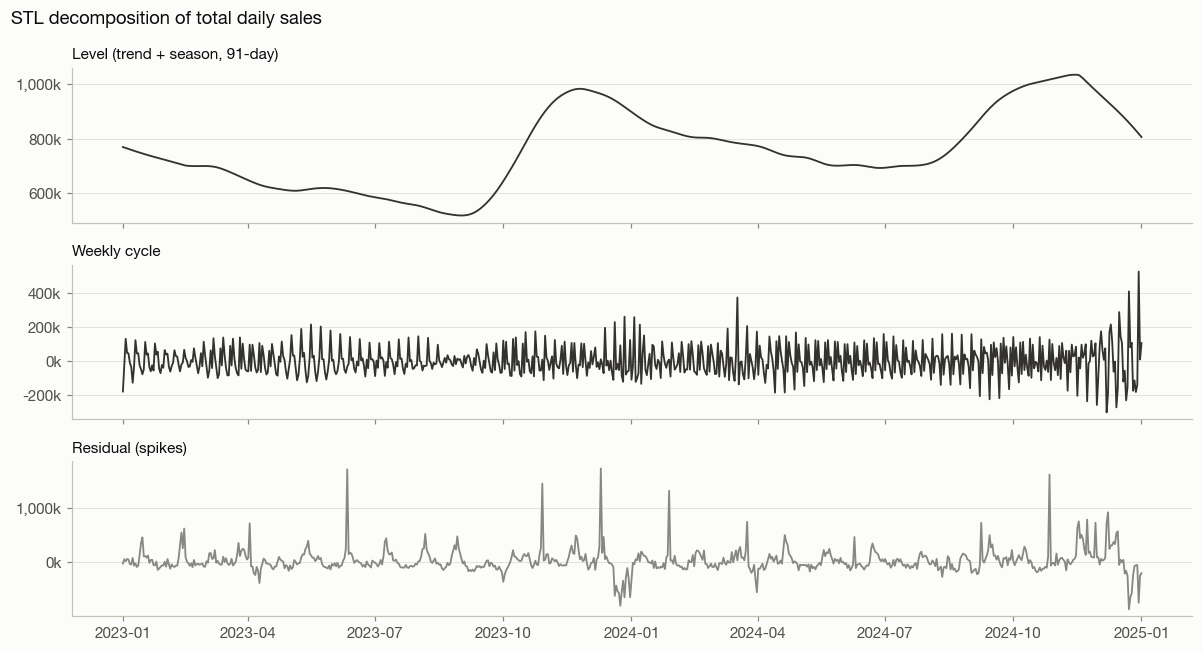

In [9]:
stl = STL(y, period=7, trend=91, robust=True).fit()
comp = pd.DataFrame({"Level (trend + season, 91-day)": stl.trend, "Weekly cycle": stl.seasonal,
                     "Residual (spikes)": stl.resid})
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, col in zip(axes, comp):
    ax.plot(comp.index, comp[col], color=MUTED if col.startswith("Residual") else TOTAL_COLOR, lw=1.2)
    ax.set_title(col, fontsize=10)
    thousands(ax, unit="k")
fig.suptitle("STL decomposition of total daily sales", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
save(fig, "01_decomposition")
print("share of variance:", (comp.var() / y.var()).round(2).to_dict())

**What we see:**

- **Trend:** sales grew about +21 % year on year, while spend grew only about +12 %.
- **Weekly pattern:** Sunday is the strongest day, followed by Tuesday. Saturday is the weakest.
- **Yearly pattern:** Q4 is the peak. Christmas (23–25 Dec) has the lowest days of the year, and Black Friday stands out.
- **September 2023 is a clear outlier.** It ran 42 days without a catalog, which is the first hint of how strongly the catalog drives demand.
- **The residual is large and spiky.** The level and the weekly cycle explain only part of the variance; the remaining daily peaks line up with catalog send-outs, so marketing has to explain them.

## 4. Marketing costs over time

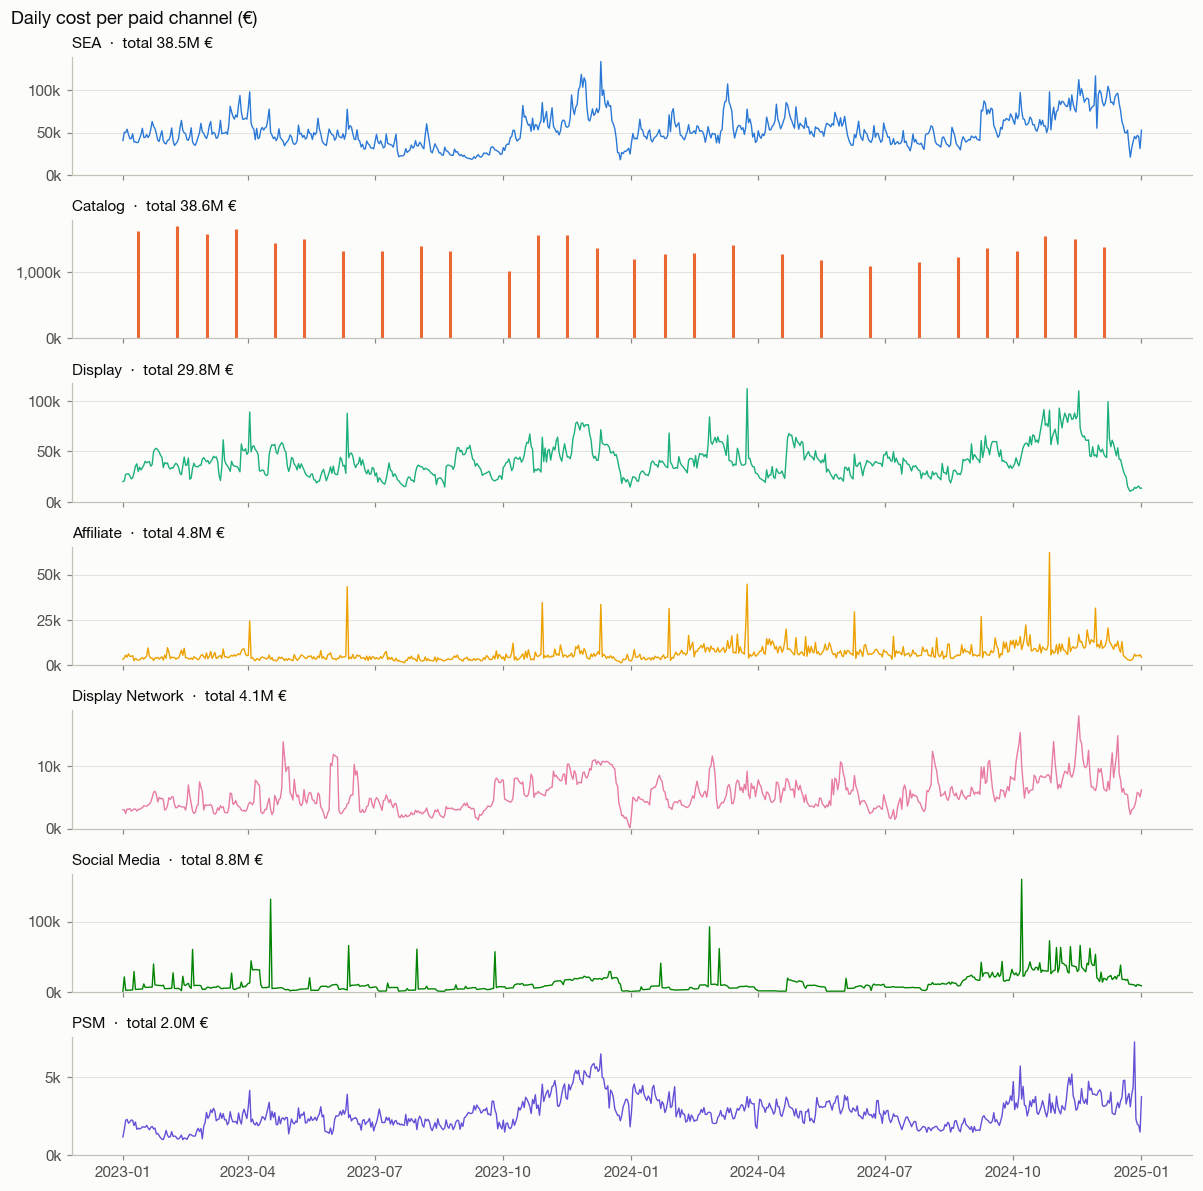

In [10]:
fig, axes = plt.subplots(len(PAID), 1, figsize=(11, 11), sharex=True)
for ax, ch in zip(axes, PAID):
    if ch == "Catalog":
        ax.vlines(costs.index, 0, costs[ch], color=CHANNEL_COLORS[ch], lw=2)
    else:
        ax.plot(costs.index, costs[ch], color=CHANNEL_COLORS[ch], lw=0.9)
    ax.set_title(f"{ch}  ·  total {costs[ch].sum() / 1e6:,.1f}M €", fontsize=10)
    thousands(ax, unit="k")
    ax.set_ylim(0)
fig.suptitle("Daily cost per paid channel (€)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
save(fig, "01_costs_by_channel");

In [11]:
dow_cost = costs[PAID].groupby(costs.index.dayofweek).mean().drop(columns="Catalog")
dow_cost.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("Catalog send-out weekdays:", pd.Series(send_outs.day_name()).value_counts().to_dict())
print("Gaps between send-outs (days):", sorted(set(np.diff(send_outs).astype("timedelta64[D]").astype(int))))
dow_cost.round(0)

Catalog send-out weekdays: {'Thursday': 26, 'Wednesday': 1, 'Friday': 1}
Gaps between send-outs (days): [np.int64(20), np.int64(21), np.int64(22), np.int64(27), np.int64(28), np.int64(35), np.int64(42)]


channel,SEA,Display,Affiliate,Display Network,Social Media,PSM
Mon,"53,760.00","40,718.00","5,215.00","5,596.00","20,054.00","2,673.00"
Tue,"52,883.00","42,478.00","6,837.00","5,435.00","10,782.00","2,972.00"
Wed,"51,036.00","41,856.00","6,202.00","5,406.00","10,334.00","2,741.00"
Thu,"49,016.00","41,232.00","6,222.00","5,412.00","10,652.00","2,693.00"
Fri,"48,598.00","39,427.00","5,823.00","5,585.00","11,115.00","2,599.00"
Sat,"50,767.00","35,672.00","5,596.00","5,520.00","10,234.00","2,560.00"
Sun,"62,103.00","43,581.00","10,314.00","6,182.00","11,172.00","2,869.00"


**What we see:**

- **Digital costs are spent every day.** They follow the season and rise together in Q4.
- **Social Media spends twice as much on Mondays,** with spikes of up to about 160 k€.
- **The Catalog is a lump of 1.0–1.7 M€ on a single day.** It goes out almost always on a Thursday, every 3 to 6 weeks.

## 5. Correlation matrix: channels vs sales (required by the brief)

,pearson,spearman
Affiliate,0.76,0.68
SEA,0.72,0.70
Display,0.56,0.50
PSM,0.49,0.49
Display Network,0.44,0.44
Social Media,0.33,0.37
Catalog,-0.01,0.00


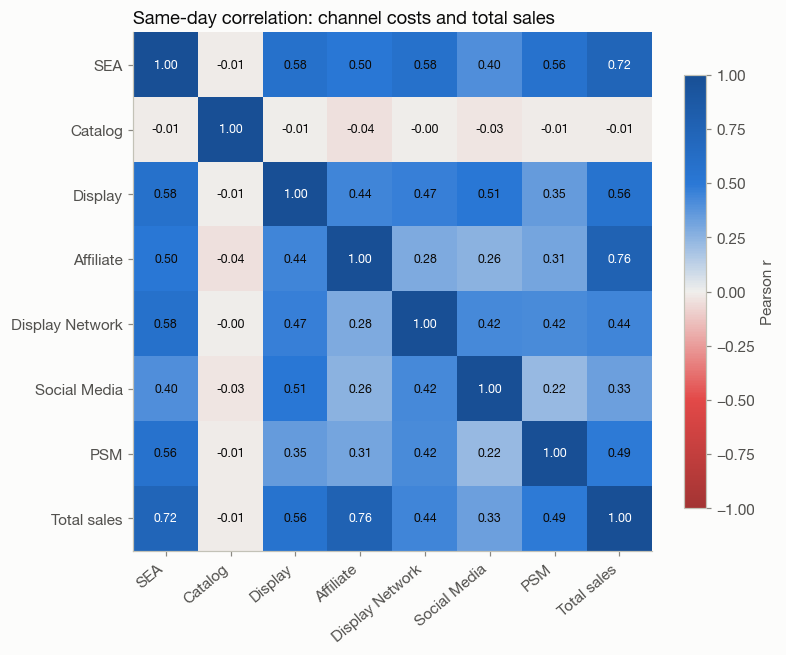

In [12]:
corr_input = costs[PAID].join(y)
pearson = corr_input.corr(method="pearson")
spearman = corr_input.corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.6, 6.4))
labels = PAID + ["Total sales"]
im = ax.imshow(pearson.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=40, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.grid(False)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = pearson.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Same-day correlation: channel costs and total sales")
save(fig, "01_corr_matrix")

pd.DataFrame({"pearson": pearson["total_sales"], "spearman": spearman["total_sales"]}).drop("total_sales") \
    .sort_values("pearson", ascending=False)

The **same-day** correlation says the Catalog does not matter (r ≈ 0). That conclusion is wrong, because catalog cost is booked on the send-out day while its effect comes days later. Lagged correlations show this:

,0,1,2,3,4,5,6,7
SEA,0.72,0.56,0.55,0.50,0.46,0.43,0.41,0.43
Catalog,-0.01,0.03,0.12,0.40,0.09,0.20,0.12,0.06
Display,0.56,0.37,0.38,0.34,0.34,0.35,0.34,0.35
Affiliate,0.76,0.26,0.32,0.26,0.24,0.25,0.18,0.26
Display Network,0.44,0.40,0.40,0.36,0.36,0.36,0.35,0.38
Social Media,0.33,0.33,0.29,0.28,0.26,0.26,0.31,0.26
PSM,0.49,0.38,0.35,0.34,0.33,0.37,0.33,0.37


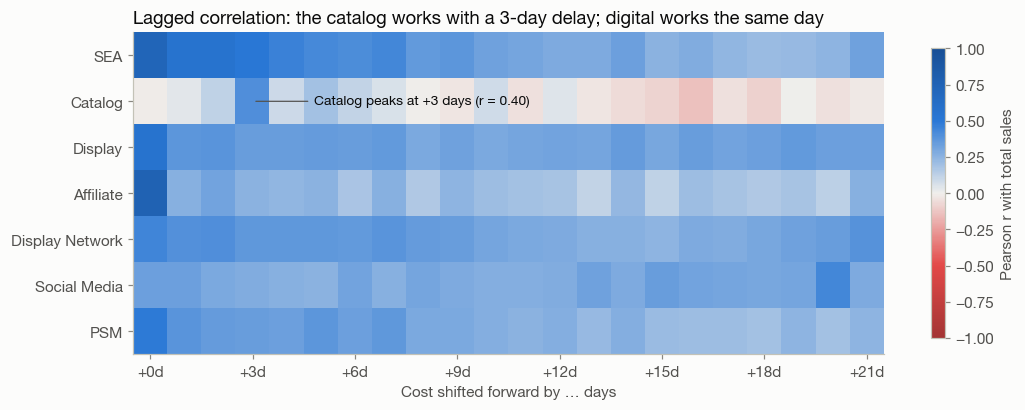

In [13]:
lags = range(0, 22)
lagged = pd.DataFrame({ch: [y.corr(costs[ch].shift(L)) for L in lags] for ch in PAID}, index=lags).T
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(lagged.values, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
ax.set_yticks(range(len(PAID)), PAID)
ax.set_xticks(range(0, 22, 3), [f"+{L}d" for L in range(0, 22, 3)])
ax.set_xlabel("Cost shifted forward by … days")
ax.grid(False)
best = int(lagged.loc["Catalog"].idxmax())
ax.annotate(f"Catalog peaks at +{best} days (r = {lagged.loc['Catalog'].max():.2f})", (best, PAID.index("Catalog")),
            xytext=(40, 0), textcoords="offset points", fontsize=9, color="#0b0b0b", va="center",
            arrowprops={"arrowstyle": "-", "color": INK_2, "lw": 0.8})
fig.colorbar(im, ax=ax, shrink=0.9, label="Pearson r with total sales")
ax.set_title("Lagged correlation: the catalog works with a 3-day delay; digital works the same day")
save(fig, "01_corr_lagged")
lagged.iloc[:, :8].round(2)

mean off-diagonal correlation of channel sales: 0.49


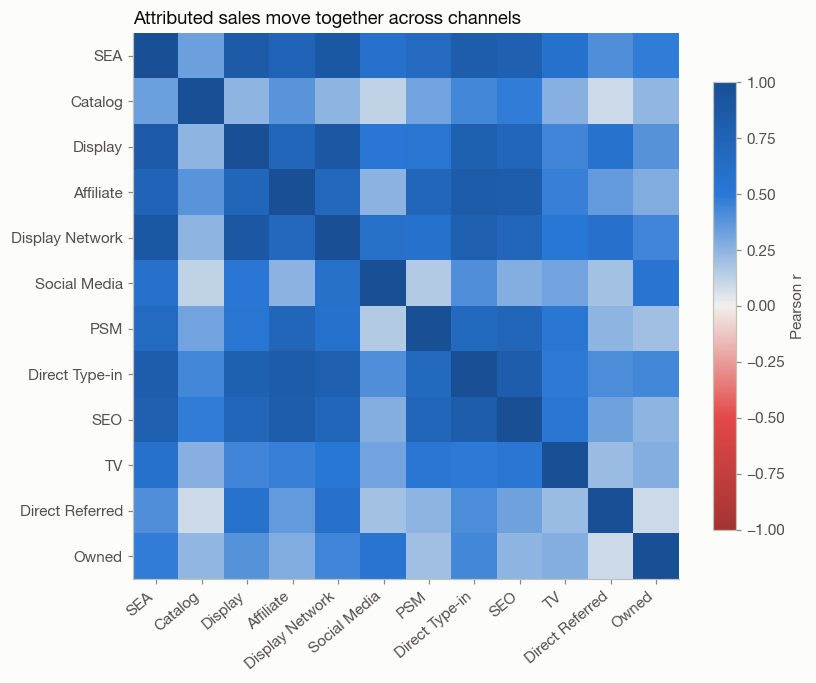

In [14]:
sales_corr = sales.corr()
fig, ax = plt.subplots(figsize=(8, 6.6))
im = ax.imshow(sales_corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(sales_corr)), sales_corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(sales_corr)), sales_corr.index)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Attributed sales move together across channels")
save(fig, "01_corr_channel_sales")
print("mean off-diagonal correlation of channel sales:",
      round(sales_corr.values[~np.eye(len(sales_corr), dtype=bool)].mean(), 2))

## 6. Catalog deep dive: delay and halo

,total,catalog
dss,,
0.00,"767,259.00","73,766.00"
1.00,"833,123.00","190,777.00"
2.00,"952,264.00","301,357.00"
3.00,"1,345,163.00","403,531.00"
4.00,"910,247.00","229,372.00"
5.00,"1,056,954.00","224,796.00"
6.00,"947,048.00","207,854.00"
7.00,"872,622.00","157,225.00"
8.00,"778,337.00","124,612.00"


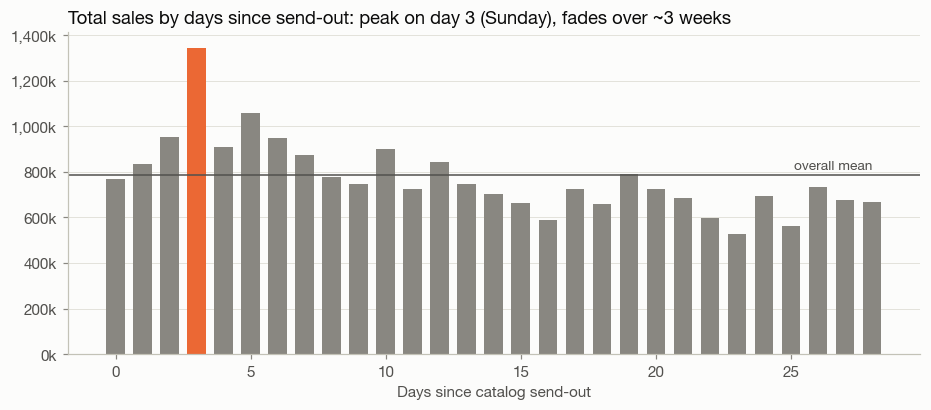

In [15]:
dss = features.days_since_send_out(y.index, send_outs)
event = pd.DataFrame({"total": y, "catalog": sales["Catalog"], "dss": dss}).dropna()
profile = event[event.dss <= 28].groupby("dss").mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
colors = [CHANNEL_COLORS["Catalog"] if d == profile.total.idxmax() else MUTED for d in profile.index]
ax.bar(profile.index, profile.total, color=colors, width=0.7)
ax.axhline(y.mean(), color=INK_2, lw=1)
ax.annotate("overall mean", (28, y.mean()), xytext=(0, 4), textcoords="offset points", ha="right",
            fontsize=9, color=INK_2)
thousands(ax, unit="k")
ax.set_xlabel("Days since catalog send-out")
ax.set_title("Total sales by days since send-out: peak on day 3 (Sunday), fades over ~3 weeks")
save(fig, "01_catalog_event_study")
profile.loc[:10].round(0)

total sales uplift in the 7 days after a send-out: +38.4%


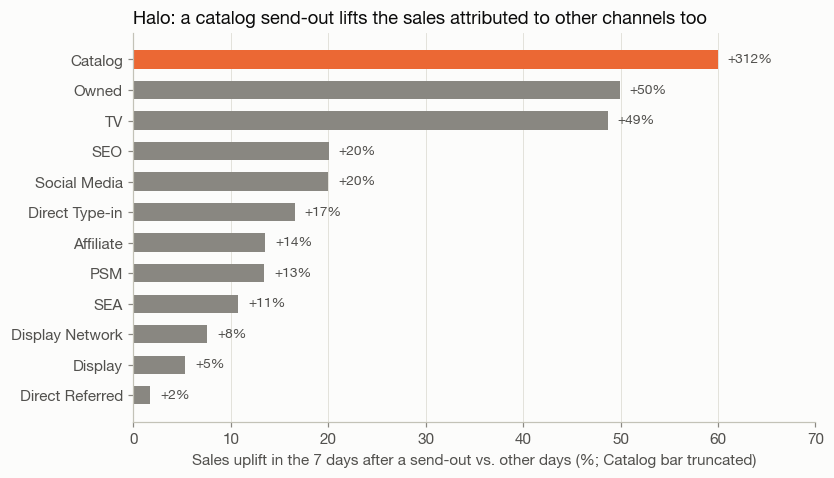

In [16]:
window = pd.Series(False, index=y.index)
for d in send_outs:
    window[(y.index > d) & (y.index <= d + pd.Timedelta(days=7))] = True
uplift = (sales[window].mean() / sales[~window].mean() - 1).sort_values()
print(f"total sales uplift in the 7 days after a send-out: {y[window].mean() / y[~window].mean() - 1:+.1%}")

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(uplift.index, uplift.clip(upper=0.6) * 100,
        color=[CHANNEL_COLORS["Catalog"] if c == "Catalog" else MUTED for c in uplift.index], height=0.6)
for i, (ch, v) in enumerate(uplift.items()):
    ax.text(min(v, 0.6) * 100 + 1, i, f"{v:+.0%}", va="center", fontsize=9, color=INK_2)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 70)
ax.set_xlabel("Sales uplift in the 7 days after a send-out vs. other days (%; Catalog bar truncated)")
ax.set_title("Halo: a catalog send-out lifts the sales attributed to other channels too")
save(fig, "01_catalog_halo");

In [17]:
top = y.nlargest(25)
near = sum(any(0 <= (d - s).days <= 7 for s in send_outs) for d in top.index)
sep = y[y.index.month == 9].groupby(y[y.index.month == 9].index.year).mean()
print(f"top-25 sales days within 7 days after a send-out: {near}/25")
print(f"September average: 2023 = {sep[2023]:,.0f} (no catalog) vs 2024 = {sep[2024]:,.0f}")

top-25 sales days within 7 days after a send-out: 20/25
September average: 2023 = 473,149 (no catalog) vs 2024 = 980,394


## 7. Efficiency KPIs and signs of reverse causality

In [18]:
kpi = {}
for ch in PAID:
    sub = raw[raw.channel == ch]
    kpi[ch] = {
        "CPC (€)": (sub.costs.sum() / sub.clicks.sum()) if sub.clicks.sum() else np.nan,
        "CPM (€)": (sub.costs.sum() / sub.impressions.sum() * 1000) if sub.impressions.sum() else np.nan,
        "r(cost, clicks)": sub.costs.corr(sub.clicks) if sub.clicks.std() > 0 else np.nan,
        "r(cost, own sales)": costs[ch].corr(sales[ch]),
        "attributed ROAS": sales[ch].sum() / costs[ch].sum(),
    }
pd.DataFrame(kpi).T.round(2)

,CPC (€),CPM (€),"r(cost, clicks)","r(cost, own sales)",attributed ROAS
SEA,0.37,6.01,0.96,0.82,3.93
Catalog,NaN,742.20,NaN,-0.07,2.07
Display,0.25,0.92,0.59,0.48,2.17
Affiliate,0.51,679.42,0.50,0.80,8.21
Display Network,0.19,1.39,0.76,0.54,3.57
Social Media,0.44,2.67,0.64,0.57,1.30
PSM,0.23,NaN,0.92,0.74,3.25


**What we see:**

- **SEA** is billed per click: cost and clicks correlate at r = 0.96. More searches mean more clicks, which means more cost, so the cost partly follows demand.
- **Affiliate** is paid as commission on sales. Its cost correlates at r = 0.80 with its own sales, so cost is partly a *result* of sales.
- **For both channels**, a naive regression will overstate the effect of spend.

## 8. Naive baselines vs the 15 % target

In [19]:
evaluate.metrics_table(y, evaluate.naive_baselines(y))[["MAE", "MAE/mean", "RMSE", "R2", "passes_15pct"]]

,MAE,MAE/mean,RMSE,R2,passes_15pct
constant mean,"205,660.93",0.26,"281,649.99",0.00,False
weekday mean,"196,323.67",0.25,"269,866.59",0.08,False
last week (lag 7),"204,740.10",0.26,"308,385.83",-0.19,False
yesterday (lag 1),"150,382.81",0.19,"253,522.57",0.19,False


None of the naive forecasts meets **MAE / mean ≤ 15 %**. Even "yesterday's value" scores about 19 %, so a model is needed.

## 9. Answers to the brief

### What conclusions do we draw from the channel interactions and the data?

1. **The Catalog is the strongest single driver, but its effect is delayed.**
   - Its same-day correlation is about −0.01. At +3 days it rises to about 0.40.
   - Total sales peak 3 days after a send-out, usually a Sunday, and fade over about 3 weeks.
   - 20 of the 25 best sales days fall within a week after a send-out.
   - September 2023, with no catalog, averaged about half the level of September 2024.
2. **The catalog creates a halo.**
   - In the week after a send-out, sales attributed to SEO (+20 %), Direct Type-in (+17 %), Affiliate (+14 %) and SEA (+11 %) rise as well.
   - Attributed ROAS therefore *understates* the catalog and overstates the channels it feeds.
   - Modelling **total** sales with an MMM captures this halo; per-channel attribution misses it.
3. **Digital budgets move together** (r = 0.2–0.6) and follow the season. Their individual effects are hard to separate (multicollinearity).
4. **SEA and Affiliate costs partly follow demand**, because they are billed per click and per sale. This reverse causality inflates their apparent effect.
5. **The baseline is strong.**
   - Direct Type-in, SEO and other unpaid channels make up about 36 % of attributed sales.
   - On top of that come the trend (+21 % year on year), the weekly pattern (Sunday and Tuesday) and Q4 seasonality.
   - A model needs calendar and trend controls next to the costs.

### What obstacles can exist in further processing?

- **Format:** long, shuffled rows that need pivoting. Dates are complete, but channel-days are missing (TV 38, Catalog 4, Owned 2).
- **Cost timing:** costs are booked on the day of causation, not the day of effect. The catalog is one lump of 1.0–1.7 M€ with a delayed, long-lasting effect, so it needs carry-over modelling (adstock) and a shift.
- **Scale:** costs differ by three orders of magnitude, from about 2.7 k€ per day (PSM) to 1.4 M€ per send-out (Catalog).
- **Correlated inputs:** multicollinearity between channels, and reverse causality for SEA and Affiliate.
- **Short history:** only 2 years, i.e. two Q4s and two Black Fridays, plus a single day of 2025.
- **Missing drivers:** no data on promotions, prices, Tchibo's weekly product "worlds", weather or competitors. This limits the achievable accuracy.

### Which of the influencing factors cannot be used?

- **`sales_by_channel` as an input:** this is target leakage, because the channel sales add up to the target.
- **`clicks` and `impressions`:**
  - They are measured on the same day as the sales and are outcomes of spend, so they are not known when the forecast is made.
  - Clicks are also partly a result of demand (SEA).
  - PSM has no impressions, and Catalog clicks are always 0.
  - The forecast has to run on the **budget**.
- **TV, SEO, Direct Type-in, Direct Referred and Owned:** they have no costs, so they cannot be budget levers. Their sales remain part of the target and are absorbed by the model baseline.